# Week 3: Model Training, Evaluation & Replenishment Logic

**Inputs:** `data/processed/weekly_product_demand.csv` (Week 1) and the Week 2 modules in `src/`.

| Deliverable | Where |
|---|---|
| Evaluated model (saved, with metadata) | `models/*.joblib` + `.json`, `reports/selected_models.csv` |
| Tuning log (validation) | `reports/model_tuning.csv` |
| Baseline comparison report | `reports/model_comparison.csv`, `reports/model_comparison_total.csv`, section 6 |
| Forecast output datasets | `data/processed/forecasts_backtest.csv`, `data/processed/forecasts_future.csv` |
| Replenishment calculation module | `src/replenishment.py` (settings in `src/config.py`) |
| Replenishment outputs | `reports/replenishment_plan.csv`, `reports/service_level_backtest.csv`, `reports/replenishment_sensitivity.csv` |
| Error analysis | `reports/error_by_product.csv`, `reports/error_by_week.csv`, `reports/error_by_demand_class.csv` |
| Error visualizations | `reports/figures/3*_*.png` |
| Documented assumptions | `reports/assumptions.md` + section 10 |

The full run takes about 5–10 minutes, mostly model tuning.

In [2]:
%pip install scikit-learn xgboost joblib pandas numpy matplotlib openpyxl

  Using cached scipy-1.17.1-cp311-cp311-win_amd64.whl.metadata (60 kB)
   ---------------------------------------- 0.0/8.3 MB ? eta -:--:--
   ---------------------------------------- 0.1/8.3 MB 1.7 MB/s eta 0:00:05
    --------------------------------------- 0.2/8.3 MB 2.1 MB/s eta 0:00:04
   -- ------------------------------------- 0.6/8.3 MB 3.9 MB/s eta 0:00:02
   ------- -------------------------------- 1.7/8.3 MB 8.1 MB/s eta 0:00:01
   --------------- ------------------------ 3.3/8.3 MB 13.2 MB/s eta 0:00:01
   ----------------------- ---------------- 4.9/8.3 MB 16.5 MB/s eta 0:00:01
   ---------------------------- ----------- 6.0/8.3 MB 17.3 MB/s eta 0:00:01
   ----------------------------------- ---- 7.4/8.3 MB 19.6 MB/s eta 0:00:01
   ---------------------------------------  8.3/8.3 MB 20.5 MB/s eta 0:00:01
   ---------------------------------------- 8.3/8.3 MB 19.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/101.7 MB ? eta -:--:--
    -------------------


[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Setup

In [3]:
import sys, json, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

from src.config import (MODEL_HORIZONS, HEADLINE_HORIZONS, LEAD_TIME_WEEKS,
                        REVIEW_PERIOD_WEEKS, SERVICE_LEVEL, ASSUMPTIONS)
from src.data_cleaning import load_weekly_panel
from src.splits import model_ready_panel, select_products, TEST_START
from src.features import make_features, extend_with_future_weeks
from src.baselines import baseline_forecasts, BASELINE_COLUMNS
from src.evaluation import metrics, evaluation_table, error_by_product
from src.models import (tune_models, select_best, fit_model, predict, add_ses,
                        training_rows, save_model, feature_importance, MAX_ABS_BIAS_PCT)
from src.replenishment import (demand_variability, replenishment_plan,
                               service_level_backtest, z_value)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORT_DIR = PROJECT_DIR / "reports"
FIG_DIR = REPORT_DIR / "figures"
MODEL_DIR = PROJECT_DIR / "models"
for d in (FIG_DIR, MODEL_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / f"{name}.png", dpi=120, bbox_inches="tight")
    plt.show()

## 2. Data, product scope and features (same rules as Week 2)

In [4]:
panel = load_weekly_panel(PROCESSED_DIR / "weekly_product_demand.csv")
selection = select_products(panel)
codes = selection.loc[selection["selected"], "StockCode"]

mp = model_ready_panel(panel)
mp = mp[mp["StockCode"].isin(codes)].reset_index(drop=True)
LAST_OBSERVED = mp["week_start"].max()

# 4 empty future weeks so the same feature code can build forecast rows after the data ends
mpf = extend_with_future_weeks(mp, n_weeks=max(MODEL_HORIZONS))

features = {h: make_features(mpf, horizon=h) for h in MODEL_HORIZONS}
baselines = {h: baseline_forecasts(mp, h) for h in MODEL_HORIZONS}

print(f"Products: {mp['StockCode'].nunique()} | observed weeks: {mp['week_start'].nunique()} "
      f"| last observed week: {LAST_OBSERVED.date()}")
print("Future weeks:", sorted(mpf.loc[mpf['split'] == 'future', 'week_start'].dt.date.unique()))

Products: 978 | observed weeks: 51 | last observed week: 2011-11-28
Future weeks: [datetime.date(2011, 12, 5), datetime.date(2011, 12, 12), datetime.date(2011, 12, 19), datetime.date(2011, 12, 26)]


## 3. Model candidates and tuning on the validation period

One **direct model per horizon** (h = 1–4), so lead-time demand can be summed over any lead time up to 4 weeks.

| Family | Candidates |
|---|---|
| **XGBoost** | squared-error loss (depth 3 / 5), log target, **Tweedie loss** (power 1.3 / 1.5, depth 3 / 5). Tweedie suits zero-heavy counts. |
| **Random Forest** | raw target and ratio-to-recent-mean target (min leaf 20 / 50), log target |
| **SES** (statistical) | simple exponential smoothing per product, α ∈ {0.1, 0.2, 0.3, 0.5} |
| **Ensemble** | equal-weight average of the best XGBoost, Random Forest and SES |

**Why not ARIMA or seasonal ETS?** Each product has only about 35 training weeks and no repeated yearly cycle, so seasonal models can't be fitted. SES is the appropriate statistical method for this data.

**Selection rule:** lowest validation WAPE among candidates with |bias| ≤ 10%.
Median-type forecasts (log target, L1 loss) score well on WAPE but under-forecast by roughly 30–40%, which would drive stockouts.
They are kept in the log but rejected.

In [5]:
tuning = pd.concat([tune_models(features[h], mpf, h, verbose=False) for h in MODEL_HORIZONS],
                   ignore_index=True)
tuning.to_csv(REPORT_DIR / "model_tuning.csv", index=False)

show = tuning.copy()
show["config"] = show["target_mode"] + " " + show["params"].str.slice(0, 70)
display(show[show["horizon"] == 1][["model", "config", "WAPE_%", "Bias_%", "MAE", "RMSE", "bias_ok"]]
        .sort_values("WAPE_%"))

,model,config,WAPE_%,Bias_%,MAE,RMSE,bias_ok
2,xgboost,"log1p {""learning_rate"": 0.05, ""n_estimators"": ...",60.09,-39.89,39.28,105.86,False
11,random_forest,"log1p {""n_estimators"": 200, ""max_features"": 0....",60.19,-38.61,39.35,105.87,False
6,xgboost,"raw {""learning_rate"": 0.05, ""n_estimators"": 40...",62.38,-11.40,40.78,100.79,False
5,xgboost,"raw {""learning_rate"": 0.05, ""n_estimators"": 40...",63.00,-6.43,41.19,98.68,True
4,xgboost,"raw {""learning_rate"": 0.05, ""n_estimators"": 40...",63.42,-8.04,41.45,100.75,True
3,xgboost,"raw {""learning_rate"": 0.05, ""n_estimators"": 40...",63.65,-4.83,41.60,99.06,True
12,ses,"raw {""alpha"": 0.1}",64.38,-7.08,42.09,99.20,True
8,random_forest,"raw {""n_estimators"": 200, ""max_features"": 0.5,...",64.41,-4.87,42.10,99.96,True
13,ses,"raw {""alpha"": 0.2}",64.51,-6.65,42.17,100.34,True
7,random_forest,"raw {""n_estimators"": 200, ""max_features"": 0.5,...",65.12,-3.36,42.57,100.37,True


In [6]:
best = select_best(tuning)
display(best[["horizon", "model", "target_mode", "params", "WAPE_%", "Bias_%", "MAE", "RMSE"]])

,horizon,model,target_mode,params,WAPE_%,Bias_%,MAE,RMSE
0,1,xgboost,raw,"{""learning_rate"": 0.05, ""n_estimators"": 400, ""...",63.00,-6.43,41.19,98.68
1,1,ses,raw,"{""alpha"": 0.1}",64.38,-7.08,42.09,99.20
2,1,random_forest,raw,"{""n_estimators"": 200, ""max_features"": 0.5, ""ma...",64.41,-4.87,42.10,99.96
3,2,xgboost,raw,"{""learning_rate"": 0.05, ""n_estimators"": 400, ""...",65.01,-7.83,42.50,101.50
4,2,ses,raw,"{""alpha"": 0.1}",65.02,-7.45,42.50,99.74
5,2,random_forest,raw,"{""n_estimators"": 200, ""max_features"": 0.5, ""ma...",65.42,-5.74,42.76,100.89
6,3,xgboost,raw,"{""learning_rate"": 0.05, ""n_estimators"": 400, ""...",65.37,-9.42,42.73,102.17
7,3,ses,raw,"{""alpha"": 0.1}",65.63,-8.02,42.90,100.40
8,3,random_forest,raw,"{""n_estimators"": 200, ""max_features"": 0.5, ""ma...",66.81,-5.57,43.67,101.75
9,4,ses,raw,"{""alpha"": 0.1}",66.19,-8.15,43.27,100.73


## 4. Validation forecasts (models fitted on train only)

In [7]:
def run_models(h, fit_splits, predict_split, cfg):
    """Fit the chosen XGBoost / RF configs on `fit_splits`, predict `predict_split`; add SES and ensemble."""
    f = features[h]
    fit_rows = training_rows(f[f["split"].isin(fit_splits)])
    target = f[f["split"] == predict_split].copy()
    out = target[["StockCode", "week_start", "origin_week", "horizon", "split", "units_sold"]].copy()
    fitted = {}
    for fam in ("xgboost", "random_forest"):
        r = cfg[(cfg["horizon"] == h) & (cfg["model"] == fam)].iloc[0]
        params = json.loads(r["params"])
        model = fit_model(fam, params, r["target_mode"], fit_rows, h)
        out[fam] = predict(model, fam, r["target_mode"], target, h)
        fitted[fam] = (model, r["target_mode"], params)
    alpha = json.loads(cfg[(cfg["horizon"] == h) & (cfg["model"] == "ses")].iloc[0]["params"])["alpha"]
    out["ses"] = add_ses(target, mpf, h, alpha)
    out["ensemble"] = out[["xgboost", "random_forest", "ses"]].mean(axis=1)
    return out, fitted, alpha

MODEL_COLUMNS = ["xgboost", "random_forest", "ses", "ensemble"]
val_fc = pd.concat([run_models(h, ["train"], "validation", best)[0] for h in MODEL_HORIZONS],
                   ignore_index=True)

val_eval = evaluation_table(val_fc, MODEL_COLUMNS, by=["horizon"])
display(val_eval)

,horizon,method,coverage_%,n,MAE,RMSE,WAPE_%,Bias_%,MAPE_%_nonzero
0,1,xgboost,100.00,7824,41.19,98.68,63.00,-6.43,194.60
1,1,random_forest,100.00,7824,42.10,99.96,64.41,-4.87,212.85
2,1,ses,100.00,7824,42.09,99.20,64.38,-7.08,207.91
3,1,ensemble,100.00,7824,41.49,98.47,63.47,-6.13,204.40
4,2,xgboost,100.00,7824,42.50,101.50,65.01,-7.83,213.90
5,2,random_forest,100.00,7824,42.76,100.89,65.42,-5.74,225.99
6,2,ses,100.00,7824,42.50,99.74,65.02,-7.45,211.54
7,2,ensemble,100.00,7824,42.23,99.76,64.60,-7.01,216.36
8,3,xgboost,100.00,7824,42.73,102.17,65.37,-9.42,210.59
9,3,random_forest,100.00,7824,43.67,101.75,66.81,-5.57,237.03


**Choosing one method for every horizon.** The dashboard, API and replenishment all use a single method.
We pick the one with the lowest **average validation WAPE over h = 1–4** whose bias is within ±10% at every horizon.

In [8]:
summary = (val_eval.groupby("method")
           .agg(mean_WAPE=("WAPE_%", "mean"), max_abs_bias=("Bias_%", lambda b: b.abs().max()))
           .sort_values("mean_WAPE"))
summary["eligible"] = summary["max_abs_bias"] <= MAX_ABS_BIAS_PCT
display(summary)
SELECTED = summary[summary["eligible"]].index[0]
print("Selected method:", SELECTED)

sel_table = best.copy()
sel_table["selected_method_overall"] = SELECTED
sel_table.to_csv(REPORT_DIR / "selected_models.csv", index=False)

,mean_WAPE,max_abs_bias,eligible
method,,,
ensemble,64.78,7.69,True
xgboost,64.90,9.62,True
ses,65.31,8.15,True
random_forest,66.01,5.74,True


Selected method: ensemble


## 5. Final evaluation on the test period (refit on train + validation)

In [9]:
test_fc = pd.concat([run_models(h, ["train", "validation"], "test", best)[0] for h in MODEL_HORIZONS],
                    ignore_index=True)

backtest = pd.concat([val_fc, test_fc], ignore_index=True)
base_all = pd.concat(baselines.values(), ignore_index=True)
backtest = backtest.merge(base_all[["StockCode", "week_start", "horizon"] + BASELINE_COLUMNS],
                          on=["StockCode", "week_start", "horizon"], how="left")
backtest["selected_method"] = SELECTED
backtest["forecast"] = backtest[SELECTED]
backtest["abs_error"] = (backtest["forecast"] - backtest["units_sold"]).abs()
backtest.to_csv(PROCESSED_DIR / "forecasts_backtest.csv", index=False)
print("Backtest forecasts:", backtest.shape)

Backtest forecasts: (62592, 17)


## 6. Baseline comparison report

In [10]:
ALL_METHODS = ["naive", "moving_avg_4", "seasonal_naive_4", "seasonal_naive_52"] + MODEL_COLUMNS
comparison = evaluation_table(backtest, ALL_METHODS, by=["horizon", "split"])
ref = (comparison[comparison["method"] == "moving_avg_4"]
       .set_index(["horizon", "split"])["WAPE_%"].rename("ma4_WAPE"))
comparison = comparison.join(ref, on=["horizon", "split"])
comparison["WAPE_improvement_vs_ma4_%"] = 100 * (1 - comparison["WAPE_%"] / comparison["ma4_WAPE"])
comparison = comparison.drop(columns="ma4_WAPE")
comparison.to_csv(REPORT_DIR / "model_comparison.csv", index=False)

cols = ["method", "MAE", "RMSE", "WAPE_%", "Bias_%", "MAPE_%_nonzero", "WAPE_improvement_vs_ma4_%"]
for h in HEADLINE_HORIZONS:
    print(f"\n=== h = {h} | TEST (8 weeks, {backtest['StockCode'].nunique()} products) ===")
    display(comparison[(comparison["horizon"] == h) & (comparison["split"] == "test")][cols]
            .sort_values("WAPE_%"))


=== h = 1 | TEST (8 weeks, 978 products) ===


,method,MAE,RMSE,WAPE_%,Bias_%,MAPE_%_nonzero,WAPE_improvement_vs_ma4_%
6,ses,44.02,121.45,59.16,-10.92,171.51,4.24
7,ensemble,45.26,123.29,60.82,2.61,199.02,1.55
1,moving_avg_4,45.97,121.51,61.78,-2.05,177.94,0.00
5,random_forest,46.82,126.33,62.91,5.79,218.53,-1.84
4,xgboost,48.19,126.50,64.76,12.95,212.96,-4.83
0,naive,54.65,154.19,73.43,0.77,184.66,-18.87
2,seasonal_naive_4,57.43,158.24,77.17,-5.29,219.88,-24.92
3,seasonal_naive_52,NaN,NaN,NaN,NaN,NaN,NaN



=== h = 4 | TEST (8 weeks, 978 products) ===


,method,MAE,RMSE,WAPE_%,Bias_%,MAPE_%_nonzero,WAPE_improvement_vs_ma4_%
54,ses,46.66,128.35,62.70,-14.65,176.97,4.70
55,ensemble,47.83,127.66,64.28,-1.10,212.93,2.30
49,moving_avg_4,48.96,130.46,65.79,-9.05,180.76,0.00
52,xgboost,49.91,128.90,67.06,5.94,217.12,-1.93
53,random_forest,50.39,130.33,67.71,5.42,251.73,-2.91
48,naive,57.43,158.24,77.17,-5.29,219.88,-17.30
50,seasonal_naive_4,57.43,158.24,77.17,-5.29,219.88,-17.30
51,seasonal_naive_52,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
# Total level: sum the product forecasts per week
tot = (backtest.groupby(["horizon", "split", "week_start"])[["units_sold"] + ALL_METHODS]
       .sum(min_count=1).reset_index())
comparison_total = evaluation_table(tot, ALL_METHODS, by=["horizon", "split"])
comparison_total.to_csv(REPORT_DIR / "model_comparison_total.csv", index=False)
display(comparison_total[(comparison_total["split"] == "test") &
                         (comparison_total["horizon"].isin(HEADLINE_HORIZONS))]
        [["horizon", "method", "MAE", "WAPE_%", "Bias_%"]].dropna().sort_values(["horizon", "WAPE_%"]))

,horizon,method,MAE,WAPE_%,Bias_%
7,1,ensemble,"6,923.23",9.51,2.61
5,1,random_forest,"7,541.90",10.36,5.79
1,1,moving_avg_4,"7,624.66",10.48,-2.05
0,1,naive,"8,816.88",12.11,0.77
6,1,ses,"9,877.23",13.57,-10.92
4,1,xgboost,"10,037.59",13.79,12.95
2,1,seasonal_naive_4,"11,947.00",16.41,-5.29
55,4,ensemble,"5,752.34",7.90,-1.10
52,4,xgboost,"7,176.67",9.86,5.94
49,4,moving_avg_4,"7,180.62",9.87,-9.05


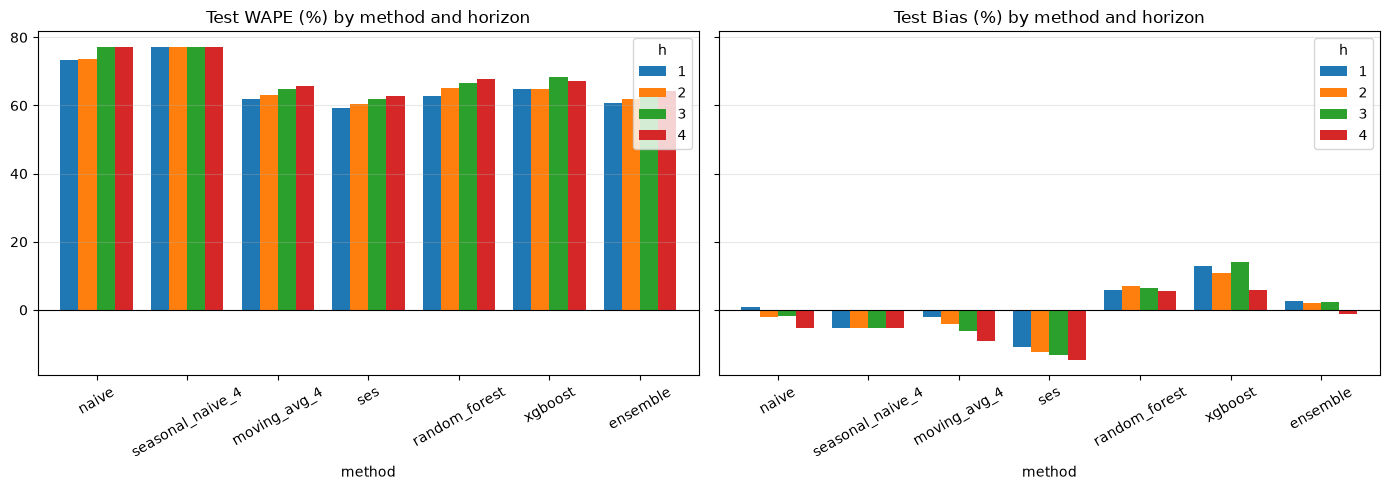

In [12]:
plot = comparison[(comparison["split"] == "test") & comparison["WAPE_%"].notna()]
order = ["naive", "seasonal_naive_4", "moving_avg_4", "ses", "random_forest", "xgboost", "ensemble"]
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, metric in zip(axes, ["WAPE_%", "Bias_%"]):
    piv = plot.pivot(index="method", columns="horizon", values=metric).reindex(order)
    piv.plot(kind="bar", ax=ax, width=0.8)
    ax.set_title(f"Test {metric.replace('_%', ' (%)')} by method and horizon")
    ax.axhline(0, color="black", linewidth=0.8); ax.grid(axis="y", alpha=0.3)
    ax.tick_params(axis="x", rotation=30); ax.legend(title="h")
save_fig("31_test_metrics_by_method")

## 7. Error analysis — by product, time period and demand pattern

In [13]:
t1 = backtest[(backtest["split"] == "test") & (backtest["horizon"] == 1)]
names = mp[["StockCode", "Description"]].drop_duplicates("StockCode")

err_prod = error_by_product(t1, "forecast").merge(names, on="StockCode")
ma4_prod = error_by_product(t1, "moving_avg_4")[["StockCode", "WAPE_%"]].rename(columns={"WAPE_%": "ma4_WAPE_%"})
err_prod = err_prod.merge(ma4_prod, on="StockCode")
err_prod["beats_ma4"] = err_prod["WAPE_%"] < err_prod["ma4_WAPE_%"]
err_prod.to_csv(REPORT_DIR / "error_by_product.csv", index=False)

print(f"{SELECTED} beats moving_avg_4 on {err_prod['beats_ma4'].mean():.0%} of products (test, h=1)")
print("Largest absolute errors:")
display(err_prod.head(10)[["StockCode", "Description", "MAE", "WAPE_%", "Bias_%", "ma4_WAPE_%"]])

ensemble beats moving_avg_4 on 44% of products (test, h=1)
Largest absolute errors:


,StockCode,Description,MAE,WAPE_%,Bias_%,ma4_WAPE_%
0,22197,POPCORN HOLDER,"1,411.58",59.30,-59.30,31.19
1,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,706.81,47.33,-40.75,77.07
2,21915,RED HARMONICA IN BOX,613.93,79.04,-12.06,83.93
3,20668,DISCO BALL CHRISTMAS DECORATION,581.26,64.29,-64.29,50.82
4,22492,MINI PAINT SET VINTAGE,439.46,61.91,-9.95,74.71
5,85099B,JUMBO BAG RED RETROSPOT,391.57,35.81,-9.61,54.58
6,17003,BROCADE RING PURSE,379.32,98.27,12.70,111.28
7,20971,PINK BLUE FELT CRAFT TRINKET BOX,363.39,84.93,0.84,118.28
8,22616,PACK OF 12 LONDON TISSUES,360.55,71.17,-12.03,67.47
9,22595,GINGHAM HEART DECORATION,342.61,77.51,-37.57,111.02


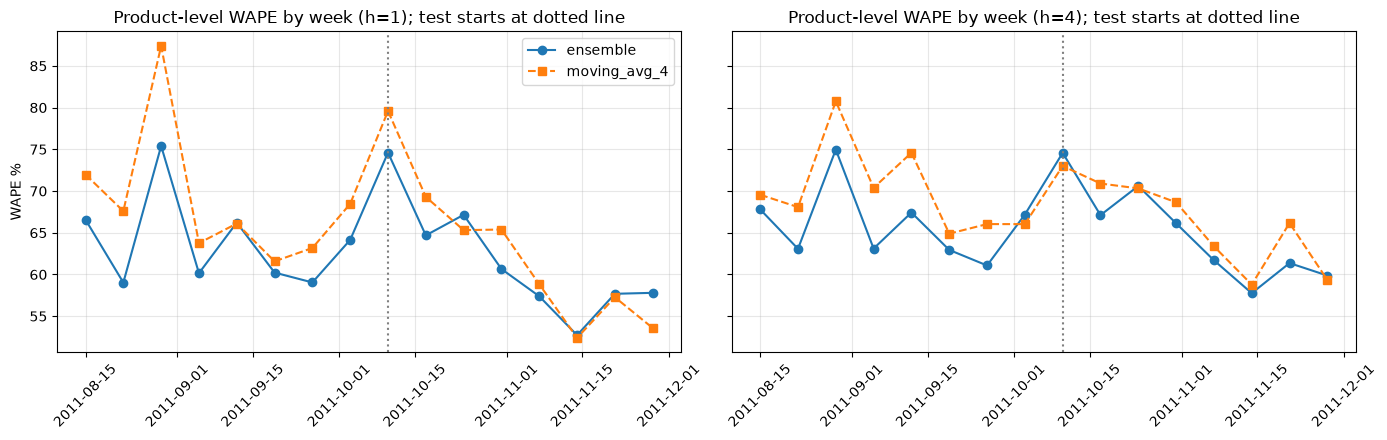

In [14]:
err_week = (backtest[backtest["horizon"].isin(HEADLINE_HORIZONS)]
            .groupby(["horizon", "split", "week_start"])
            .apply(lambda g: pd.Series({
                "actual": g["units_sold"].sum(),
                f"{SELECTED}_WAPE_%": 100 * (g["forecast"] - g["units_sold"]).abs().sum() / g["units_sold"].sum(),
                "moving_avg_4_WAPE_%": 100 * (g["moving_avg_4"] - g["units_sold"]).abs().sum() / g["units_sold"].sum(),
                f"{SELECTED}_Bias_%": 100 * (g["forecast"] - g["units_sold"]).sum() / g["units_sold"].sum(),
            }), include_groups=False).reset_index())
err_week.to_csv(REPORT_DIR / "error_by_week.csv", index=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, h in zip(axes, HEADLINE_HORIZONS):
    d = err_week[err_week["horizon"] == h].sort_values("week_start")
    ax.plot(d["week_start"], d[f"{SELECTED}_WAPE_%"], "o-", label=SELECTED)
    ax.plot(d["week_start"], d["moving_avg_4_WAPE_%"], "s--", label="moving_avg_4")
    ax.axvline(TEST_START, color="grey", linestyle=":")
    ax.set_title(f"Product-level WAPE by week (h={h}); test starts at dotted line")
    ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("WAPE %"); axes[0].legend()
save_fig("32_error_by_week")

In [15]:
profile = pd.read_csv(REPORT_DIR / "demand_profile.csv", dtype={"StockCode": str})
by_class = (t1.merge(profile[["StockCode", "demand_class"]], on="StockCode", how="left")
              .groupby("demand_class")
              .apply(lambda g: pd.Series({
                  "products": g["StockCode"].nunique(),
                  f"{SELECTED}_WAPE_%": 100 * g["abs_error"].sum() / g["units_sold"].sum(),
                  "moving_avg_4_WAPE_%": 100 * (g["moving_avg_4"] - g["units_sold"]).abs().sum() / g["units_sold"].sum(),
                  f"{SELECTED}_Bias_%": 100 * (g["forecast"] - g["units_sold"]).sum() / g["units_sold"].sum(),
              }), include_groups=False).reset_index())
by_class.to_csv(REPORT_DIR / "error_by_demand_class.csv", index=False)
display(by_class)
print("Demand classes come from the Week 1 profile (descriptive grouping only, not a model input).")

,demand_class,products,ensemble_WAPE_%,moving_avg_4_WAPE_%,ensemble_Bias_%
0,erratic,797.00,65.57,67.42,-1.18
1,intermittent,3.00,438.35,197.73,335.44
2,lumpy,50.00,"1,038.11",294.64,953.64
3,smooth,128.00,45.50,45.40,11.43


Demand classes come from the Week 1 profile (descriptive grouping only, not a model input).


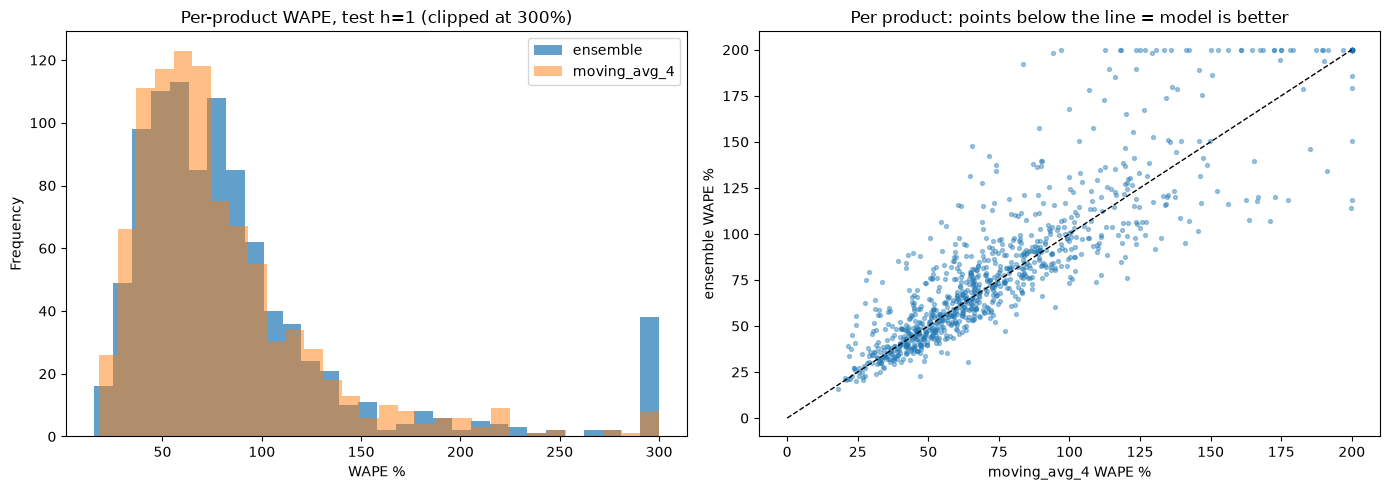

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
err_prod["WAPE_%"].clip(upper=300).plot(kind="hist", bins=30, ax=axes[0], alpha=0.7, label=SELECTED)
err_prod["ma4_WAPE_%"].clip(upper=300).plot(kind="hist", bins=30, ax=axes[0], alpha=0.5, label="moving_avg_4")
axes[0].set_title("Per-product WAPE, test h=1 (clipped at 300%)"); axes[0].set_xlabel("WAPE %"); axes[0].legend()

lim = err_prod[["WAPE_%", "ma4_WAPE_%"]].clip(upper=200)
axes[1].scatter(lim["ma4_WAPE_%"], lim["WAPE_%"], s=8, alpha=0.4)
axes[1].plot([0, 200], [0, 200], "k--", linewidth=1)
axes[1].set_xlabel("moving_avg_4 WAPE %"); axes[1].set_ylabel(f"{SELECTED} WAPE %")
axes[1].set_title("Per product: points below the line = model is better")
save_fig("33_error_by_product")

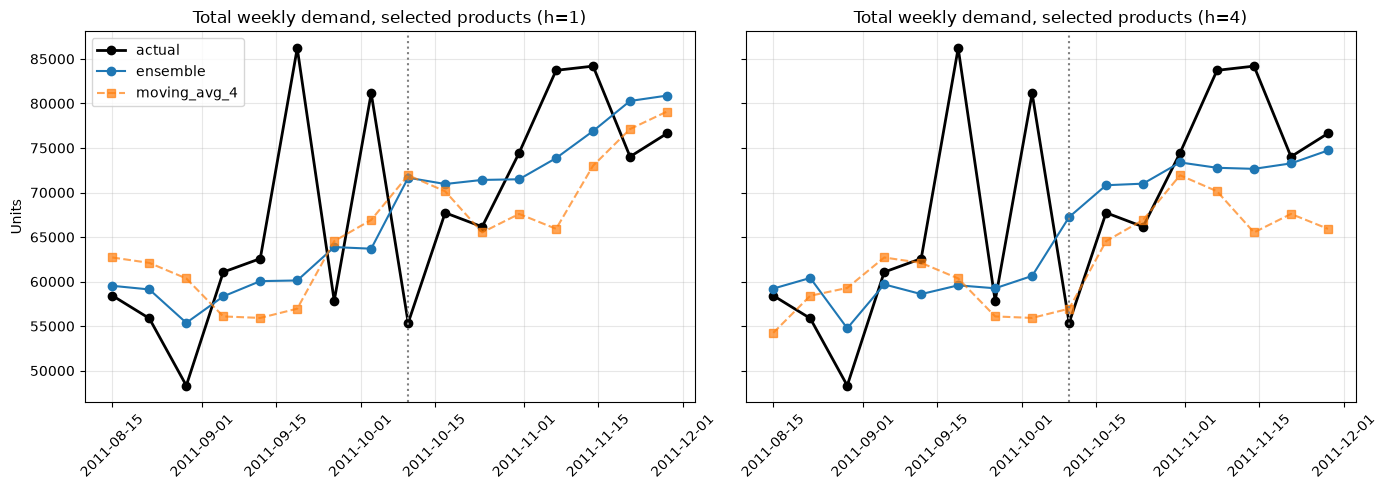

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, h in zip(axes, HEADLINE_HORIZONS):
    d = tot[tot["horizon"] == h].sort_values("week_start")
    ax.plot(d["week_start"], d["units_sold"], "k-o", linewidth=2, label="actual")
    ax.plot(d["week_start"], d[SELECTED], "o-", label=SELECTED)
    ax.plot(d["week_start"], d["moving_avg_4"], "s--", alpha=0.7, label="moving_avg_4")
    ax.axvline(TEST_START, color="grey", linestyle=":")
    ax.set_title(f"Total weekly demand, selected products (h={h})")
    ax.grid(alpha=0.3); ax.tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Units"); axes[0].legend()
save_fig("34_total_actual_vs_forecast")

## 8. Production models and future forecasts

For forecasting beyond the data, the selected configurations are refitted on **all observed weeks** (train + validation + test).
The forecast origin is the last complete week. The test scores above come from the train + validation models, so they are unaffected.

In [18]:
future_rows, importances = [], {}
for h in MODEL_HORIZONS:
    f = features[h]
    target = f[(f["split"] == "future") & (f["origin_week"] == LAST_OBSERVED)].copy()
    fit_rows = training_rows(f[f["split"].isin(["train", "validation", "test"])])
    out = target[["StockCode", "Description", "week_start", "origin_week", "horizon"]].copy()
    for fam in ("xgboost", "random_forest"):
        r = best[(best["horizon"] == h) & (best["model"] == fam)].iloc[0]
        params = json.loads(r["params"])
        model = fit_model(fam, params, r["target_mode"], fit_rows, h)
        out[fam] = predict(model, fam, r["target_mode"], target, h)
        save_model(model, MODEL_DIR / f"{fam}_h{h}.joblib",
                   {"model": fam, "horizon": h, "target_mode": r["target_mode"], "params": params,
                    "trained_on": "all observed weeks", "last_observed_week": LAST_OBSERVED.date(),
                    "validation_WAPE_%": round(r["WAPE_%"], 2)})
        if fam == "xgboost":
            importances[h] = feature_importance(model, h)
    alpha = json.loads(best[(best["horizon"] == h) & (best["model"] == "ses")].iloc[0]["params"])["alpha"]
    out["ses"] = add_ses(target, mpf, h, alpha)
    out["ensemble"] = out[["xgboost", "random_forest", "ses"]].mean(axis=1)
    out["selected_method"] = SELECTED
    out["forecast"] = out[SELECTED]
    future_rows.append(out)

forecasts_future = pd.concat(future_rows, ignore_index=True)
forecasts_future.to_csv(PROCESSED_DIR / "forecasts_future.csv", index=False)

(MODEL_DIR / "model_card.json").write_text(json.dumps({
    "selected_method": SELECTED, "horizons": list(MODEL_HORIZONS),
    "products": int(mp["StockCode"].nunique()), "last_observed_week": str(LAST_OBSERVED.date()),
    "ses_alpha_by_horizon": {int(h): json.loads(best[(best["horizon"] == h) & (best["model"] == "ses")].iloc[0]["params"])["alpha"]
                             for h in MODEL_HORIZONS},
    "selection_rule": f"lowest mean validation WAPE (h=1-4) with |bias| <= {MAX_ABS_BIAS_PCT}%",
}, indent=2))

print("Future forecast weeks:", sorted(forecasts_future["week_start"].dt.date.unique()))
display(forecasts_future.groupby("week_start")[["forecast"]].sum())
print("Saved models:", sorted(p.name for p in MODEL_DIR.glob("*.joblib")))

Future forecast weeks: [datetime.date(2011, 12, 5), datetime.date(2011, 12, 12), datetime.date(2011, 12, 19), datetime.date(2011, 12, 26)]


,forecast
week_start,
2011-12-05,"75,700.20"
2011-12-12,"77,606.30"
2011-12-19,"78,198.65"
2011-12-26,"64,600.72"


Saved models: ['random_forest_h1.joblib', 'random_forest_h2.joblib', 'random_forest_h3.joblib', 'random_forest_h4.joblib', 'xgboost_h1.joblib', 'xgboost_h2.joblib', 'xgboost_h3.joblib', 'xgboost_h4.joblib']


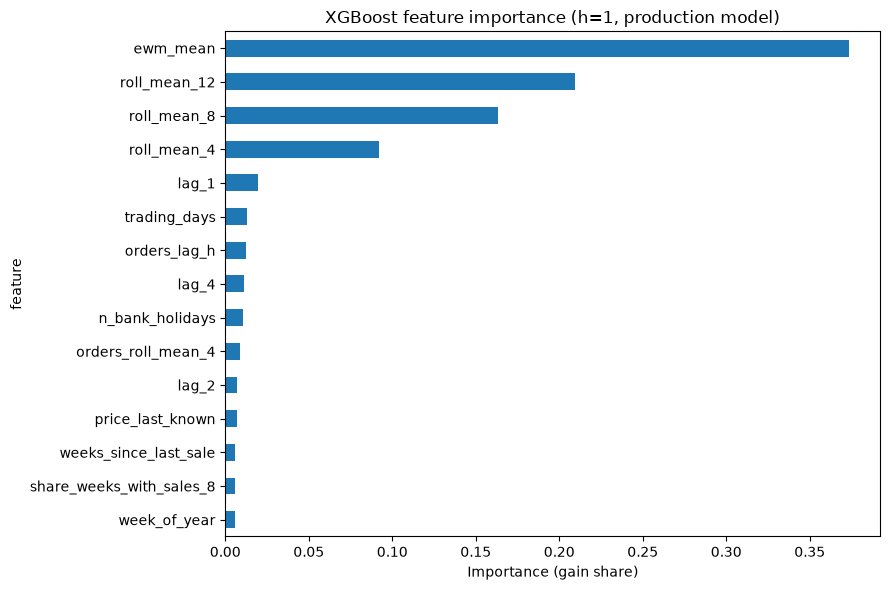

In [19]:
imp = importances[1].head(15).iloc[::-1]
imp.plot(x="feature", y="importance", kind="barh", figsize=(9, 6), legend=False,
         title="XGBoost feature importance (h=1, production model)")
plt.xlabel("Importance (gain share)")
save_fig("35_feature_importance_h1")

The week of **26 Dec 2011** contains two bank holidays, and the shop was closed for the whole of the same week in 2010.
Its forecast assumes 4 trading days and is probably too high. Planners should treat that week as a likely closure.

## 9. Replenishment logic

`src/replenishment.py` implements a **periodic-review, order-up-to policy**. With lead time *L*, review period *R* and service level *SL* (z = Φ⁻¹(SL)):

| Quantity | Formula |
|---|---|
| Lead-time demand | sum of forecasts for weeks 1 … L |
| Demand variability σ | RMSE of out-of-sample **cumulative** forecast errors per product (validation period, models fitted on train only) |
| Safety stock | z × σ(L+R) |
| Reorder point | lead-time demand + z × σ(L) |
| Order-up-to level | forecast demand over L+R + safety stock |
| Suggested order | max(0, order-up-to − inventory position), rounded to pack size, MOQ applied |
| Stockout risk | P(lead-time demand > inventory position) under a normal approximation |

**Current stock is not in the dataset**, so the module takes it as an input. Without it, the plan reports reorder points and order-up-to levels, and the stock-dependent columns stay empty.

In [20]:
L, R, SL = LEAD_TIME_WEEKS, REVIEW_PERIOD_WEEKS, SERVICE_LEVEL
P = L + R
val_sel = val_fc.assign(forecast=val_fc[SELECTED])
test_sel = test_fc.assign(forecast=test_fc[SELECTED])

sigma_L = demand_variability(val_sel, L)
sigma_P = demand_variability(val_sel, P)
print(f"Assumptions: lead time {L} wk, review {R} wk, service level {SL:.0%} → z = {z_value(SL):.3f}")
display(sigma_L.describe())

Assumptions: lead time 2 wk, review 1 wk, service level 95% → z = 1.645


,sigma_2w,n_origins
count,978.00,978.00
mean,83.24,7.00
std,115.27,0.00
min,2.30,7.00
25%,21.12,7.00
50%,44.53,7.00
75%,88.56,7.00
max,985.13,7.00


In [21]:
# Does the safety stock deliver the target service level? Check on the unseen test period.
bt = service_level_backtest(test_sel, sigma_L, lead_time=L, service_level=SL)
bt.to_csv(REPORT_DIR / "service_level_backtest.csv", index=False)
print(f"Lead-time demand cycles checked on test: {len(bt):,} (products × origins)")
print(f"Covered WITHOUT safety stock (forecast only): {bt['covered_without_safety_stock'].mean():.1%}")
print(f"Covered WITH safety stock:                    {bt['covered'].mean():.1%}  (target {SL:.0%})")

check = []
for sl in (0.90, 0.95, 0.99):
    b = service_level_backtest(test_sel, sigma_L, lead_time=L, service_level=sl)
    check.append({"target_service_level": sl, "achieved_on_test": b["covered"].mean()})
display(pd.DataFrame(check))

Lead-time demand cycles checked on test: 6,846 (products × origins)
Covered WITHOUT safety stock (forecast only): 67.0%
Covered WITH safety stock:                    91.0%  (target 95%)


,target_service_level,achieved_on_test
0,0.90,0.88
1,0.95,0.91
2,0.99,0.94


In [22]:
plan = replenishment_plan(forecasts_future[["StockCode", "horizon", "forecast"]], sigma_L, sigma_P)
plan = names.merge(plan, on="StockCode")
plan.to_csv(REPORT_DIR / "replenishment_plan.csv", index=False)
print(f"Plan for {len(plan)} products from origin {LAST_OBSERVED.date()} "
      f"(stock-dependent columns empty until stock is provided)")
display(plan.sort_values("lead_time_demand", ascending=False).head(10)
        [["StockCode", "Description", "forecast_next_week", "lead_time_demand",
          "safety_stock", "reorder_point", "order_up_to_level"]])

Plan for 978 products from origin 2011-11-28 (stock-dependent columns empty until stock is provided)


,StockCode,Description,forecast_next_week,lead_time_demand,safety_stock,reorder_point,order_up_to_level
411,22197,POPCORN HOLDER,"1,537.78","3,096.14",852.00,"4,007.00","5,434.00"
955,85099B,JUMBO BAG RED RETROSPOT,"1,071.36","2,154.49","2,131.00","3,724.00","5,343.00"
886,84077,WORLD WAR 2 GLIDERS ASSTD DESIGNS,"1,057.33","2,124.31",867.00,"2,906.00","4,082.00"
24,20668,DISCO BALL CHRISTMAS DECORATION,933.25,"1,976.82",257.00,"2,197.00","3,172.00"
916,84879,ASSORTED COLOUR BIRD ORNAMENT,958.68,"1,969.37",628.00,"2,474.00","3,597.00"
959,85123A,WHITE HANGING HEART T-LIGHT HOLDER,833.52,"1,731.31",510.00,"2,261.00","3,086.00"
255,21790,VINTAGE SNAP CARDS,625.83,"1,285.45","1,009.00","1,957.00","2,886.00"
298,21915,RED HARMONICA IN BOX,598.12,"1,278.90","1,912.00","2,704.00","3,840.00"
544,22492,MINI PAINT SET VINTAGE,626.56,"1,262.57","1,416.00","2,091.00","3,340.00"
129,21212,PACK OF 72 RETROSPOT CAKE CASES,550.16,"1,230.72",930.00,"2,175.00","2,799.00"


In [23]:
# HOW TO USE WITH REAL STOCK: pass a table of on-hand (and optionally on-order) units.
# The numbers below are a typed-in illustration of the input format, not data.
example_stock = pd.DataFrame({
    "StockCode": plan.sort_values("lead_time_demand", ascending=False)["StockCode"].head(3).tolist(),
    "on_hand":   [500, 2000, 50],
    "on_order":  [0, 0, 100],
})
example = replenishment_plan(forecasts_future[["StockCode", "horizon", "forecast"]],
                             sigma_L, sigma_P, stock=example_stock)
display(example[example["StockCode"].isin(example_stock["StockCode"])]
        [["StockCode", "lead_time_demand", "reorder_point", "order_up_to_level", "inventory_position",
          "reorder_now", "suggested_order_qty", "stockout_risk_lead_time", "weeks_of_cover"]])

,StockCode,lead_time_demand,reorder_point,order_up_to_level,inventory_position,reorder_now,suggested_order_qty,stockout_risk_lead_time,weeks_of_cover
411,22197,"3,096.14","4,007.00","5,434.00",500.00,True,"4,934.00",1.00,0.33
886,84077,"2,124.31","2,906.00","4,082.00",150.00,True,"3,932.00",1.00,0.14
955,85099B,"2,154.49","3,724.00","5,343.00","2,000.00",True,"3,343.00",0.56,1.87


service_level,0.90,0.95,0.99
lead_time_weeks,,,
1,"104,816.00","134,376.00","189,873.00"
2,"136,840.00","175,485.00","247,996.00"
3,"163,678.00","209,954.00","296,721.00"


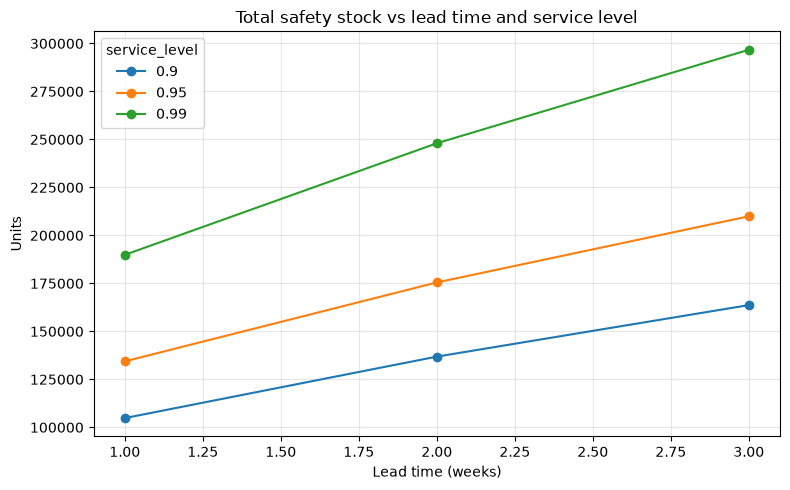

In [24]:
# Sensitivity of total safety stock to the two key assumptions
rows = []
for lt in (1, 2, 3):
    for sl in (0.90, 0.95, 0.99):
        sL = demand_variability(val_sel, lt)
        sP = demand_variability(val_sel, lt + R)
        p = replenishment_plan(forecasts_future[["StockCode", "horizon", "forecast"]], sL, sP,
                               lead_time=lt, service_level=sl)
        rows.append({"lead_time_weeks": lt, "service_level": sl,
                     "total_safety_stock_units": p["safety_stock"].sum(),
                     "total_reorder_point_units": p["reorder_point"].sum()})
sens = pd.DataFrame(rows)
sens.to_csv(REPORT_DIR / "replenishment_sensitivity.csv", index=False)
display(sens.pivot(index="lead_time_weeks", columns="service_level", values="total_safety_stock_units"))

ax = sens.pivot(index="lead_time_weeks", columns="service_level",
                values="total_safety_stock_units").plot(marker="o", figsize=(8, 5))
ax.set_title("Total safety stock vs lead time and service level")
ax.set_xlabel("Lead time (weeks)"); ax.set_ylabel("Units"); ax.grid(alpha=0.3)
save_fig("36_safety_stock_sensitivity")

## 10. Documented assumptions and limitations

In [25]:
assump = pd.DataFrame(ASSUMPTIONS, columns=["Assumption", "Value used", "Notes"])
display(assump)

lines = ["# Assumptions and limitations (Week 3)", "",
         "All inventory parameters are **assumptions**. None of them comes from the dataset. They are set in `src/config.py`.", "",
         "| Assumption | Value used | Notes |", "|---|---|---|"]
lines += [f"| {a} | {v} | {n} |" for a, v, n in ASSUMPTIONS]
lines += ["", "## Model limitations", "",
          "- **Only about 12 months of data:** yearly seasonality cannot be learned. Validation and test fall in the autumn ramp-up and the pre-Christmas peak.",
          f"- **Selection rule:** the selected method (`{SELECTED}`) was chosen on validation, using the lowest mean WAPE with |bias| ≤ {MAX_ABS_BIAS_PCT}%. The test period was used once, for the final comparison.",
          "- **Noisy product-level demand:** product-level WAPE stays high (about 60–70%) because weekly demand per product is noisy and often intermittent. Total-level error is much lower.",
          "- **Hidden stockouts:** the data has no stockout or inventory history, so if stockouts happened, the forecasts and safety stock are understated.",
          "- **No promotion data:** promotions cannot be modelled.",
          "- **Christmas week:** the 26 Dec 2011 forecast assumes the shop trades 4 days. In 2010 it was closed that week.",
          "- **Normal approximation:** the safety stock uses a normal approximation, which is less accurate for intermittent items. The test backtest in `reports/service_level_backtest.csv` shows the service level actually achieved.",
          f"- **Service level below target:** on the test period, a {SL:.0%} target achieved {bt['covered'].mean():.1%}. Setting 99% achieved about {check[-1]['achieved_on_test']:.0%}. The variability estimate comes from only 7 validation cycles per product, and peak-season risk is higher.",
          "- **Products being phased out:** for products whose demand collapses, forecasts lag the drop by several weeks. Flag products with `trend_4_vs_12 < 0.5` for manual review."]
(REPORT_DIR / "assumptions.md").write_text("\n".join(lines), encoding="utf-8")
print("Saved reports/assumptions.md")

,Assumption,Value used,Notes
0,Lead time,2 weeks for every product,No supplier data. Configurable from 1 to 4 wee...
1,Review period,1 week,"Orders are placed weekly (periodic review, ord..."
2,Service level,95% cycle service level,Probability of not running out during lead tim...
3,Demand variability,RMSE of out-of-sample cumulative forecast erro...,Measured on the validation period with models ...
4,Error distribution,Normal approximation,z = NormalDist().inv_cdf(service level). Appro...
5,Current stock,User input only,Not in the dataset. Outputs that need it stay ...
6,Pack size / MOQ,1 / 0,No supplier data; orders are rounded to whole ...
7,Stockouts in history,Not identifiable,Sales are treated as demand. If stockouts occu...
8,Promotions,Not available,Only a past price-change proxy is used as a fe...


Saved reports/assumptions.md


## 11. Summary

**Selected model: equal-weight ensemble of XGBoost (Tweedie loss), Random Forest and SES.**
It was chosen on validation only, using the lowest mean WAPE across h = 1–4 with |bias| ≤ 10%. It is used for every horizon.

**Validation (where the choice was made)**

| | Ensemble WAPE | moving_avg_4 WAPE | Improvement |
|---|---|---|---|
| h = 1 | 63.2% | 68.0% | 7.0% |
| h = 4 | 66.1% | 69.4% | 4.7% |

**Test (8 unseen weeks, used once)**

| | Metric | Ensemble | moving_avg_4 | Best of the rest |
|---|---|---|---|---|
| h = 1 | WAPE / Bias | **60.6% / +2.3%** | 61.8% / −2.1% | SES 59.2% / −10.9% |
| h = 1 | MAE / RMSE | 45.1 / 122.9 | 46.0 / 121.5 | |
| h = 4 | WAPE / Bias | **65.2% / +1.3%** | 65.8% / −9.1% | SES 62.7% / −14.7% |
| h = 4 | MAE / RMSE | 48.6 / 128.2 | 49.0 / 130.5 | |
| Total demand, h = 1 | WAPE | **9.4%** | 10.5% | |
| Total demand, h = 4 | WAPE | **8.0%** | 9.9% | |

**Interpretation**
- **Small product-level gain:** the improvement over a well-chosen baseline is modest on test (1–2% WAPE). Weekly product demand is very noisy and the test period is the unseen pre-Christmas peak.
- **Where the model adds value:** it is almost **unbiased** (+1–2% against −2% to −9% for the moving average), and it is clearly better at total-demand level. Both matter more for replenishment than product-level WAPE alone.
- **SES on test:** SES has the lowest test WAPE, but it under-forecasts by 11–15% and was not the best on validation. Switching to it after seeing the test results would be test-set tuning, so the validation choice stands.
- **XGBoost and Random Forest alone:** each over-forecasts on test (+12% and +6%) after being refitted with the rising validation weeks. Averaging the three methods cancels these opposite biases.
- **By product:** the ensemble beats the moving average on 45% of products, but on the higher-volume ones. 68 products have WAPE above 300%. These are products being phased out, whose demand collapses in the test period, and together they account for only about 2% of total absolute error. The Week 4 dashboard should flag sharp drops (`trend_4_vs_12 < 0.5`) for manual review.

**Replenishment** (lead time 2 weeks, weekly review, 95% target, all assumptions)
- **Safety stock is needed:** without it, the forecast alone covers lead-time demand in only 66.7% of test cycles. With it, coverage is **90.8%** (target 95%).
- **The 95% target falls short in practice:** the normal approximation and a variability estimate from 7 validation cycles understate peak-season risk. Setting 99% achieves about 94% on test. Use a higher setting, or recalibrate once more history is available.
- **Total safety stock:** 175,623 units across 978 products at these assumptions. `reports/replenishment_sensitivity.csv` shows how it changes with lead time and service level.
- **Stock-dependent outputs:** these need current stock as an input, because the dataset has none.

**Outputs for Week 4:** `models/` holds 8 production models plus `model_card.json`, `data/processed/forecasts_future.csv` holds forecasts for 5–26 Dec 2011, and `reports/replenishment_plan.csv` holds the restocking plan.
